## Classification

### Calculate the sigmoid function

In [1]:
import numpy as np

def sigmoid(z):
    g = 1/(1+ np.exp(-z))
    return g

In [2]:
print(sigmoid(0))
print(sigmoid(100))
print(sigmoid(-100))

0.5
1.0
3.7200759760208356e-44


### Cost

In [3]:
def compute_cost_logistic(X,y,w,b):
    m=X.shape[0]
    cost=0.0

    for i in range(m):
        z_i = np.dot(X[i],w)+ b
        f_wb_i= sigmoid(z_i)
        cost = cost - y[i]*np.log(f_wb_i) - (1-y[i])*np.log(1-f_wb_i)

    cost = cost/m
    return cost

In [4]:
X_train = np.array([[0.5, 1.5], [1,1], [1.5, 0.5], [3, 0.5], [2, 2], [1, 2.5]])  #(m,n)
y_train = np.array([0, 0, 0, 1, 1, 1])       

w_tmp = np.array([1,1])
b_tmp=-3

print(compute_cost_logistic(X_train,y_train, w_tmp , b_tmp))                                    #(m,)

0.36686678640551745


#### lets observe cost function for different value of w

Cost for b = -3 :  0.36686678640551745
Cost for b = -4 :  0.5036808636748461


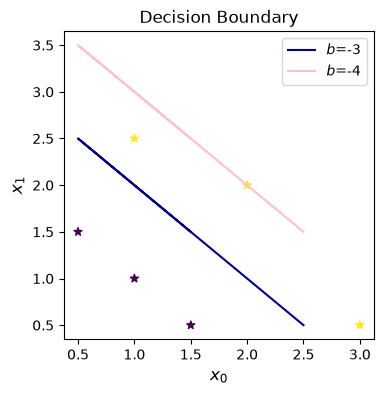

In [5]:
import matplotlib.pyplot as plt

x0 = X_train[:,1] #use only one row for plotting now 
x1 = 3 - x0
x1_other = 4- x0

plt.figure(figsize=(4,4))
plt.plot(x0,x1, c='darkblue' , label=r"$b$=-3")
plt.plot(x0,x1_other, c='pink', label= r"$b$=-4")
plt.legend(loc="upper right")
plt.ylabel('$x_1$', fontsize=12)
plt.xlabel('$x_0$', fontsize=12)
plt.title("Decision Boundary")


plt.scatter(X_train[:,0],X_train[:,1], c=y_train, marker='*')


w_array1 = np.array([1,1])
b_1 = -3
w_array2 = np.array([1,1])
b_2 = -4

print("Cost for b = -3 : ", compute_cost_logistic(X_train, y_train, w_array1, b_1))
print("Cost for b = -4 : ", compute_cost_logistic(X_train, y_train, w_array2, b_2))

### Gradient Descent for logistic 

In [6]:
def compute_gradient_logistic(X,y,w,b):
    m,n = X.shape

    dj_dw= np.zeros((n,))
    dj_db= 0.0

    for i in range(m): #for each column
        z = np.dot(X[i],w) + b
        f_wb_i = sigmoid(z) 

        err_i= f_wb_i - y[i]

        for j in range(n): #for each row
            dj_dw[j] = dj_dw[j] + err_i * X[i,j]
        
        dj_db = dj_db + err_i

    dj_dw = dj_dw/m
    dj_db = dj_db/m

    return dj_db, dj_dw

In [18]:
X_tmp = np.array([[0.5, 1.5], [1,1], [1.5, 0.5], [3, 0.5], [2, 2], [1, 2.5]])
y_tmp = np.array([0, 0, 0, 1, 1, 1])
w_tmp = np.array([2.,3.])
b_tmp = 1.
dj_db_tmp, dj_dw_tmp = compute_gradient_logistic(X_tmp, y_tmp, w_tmp, b_tmp)
print(f"dj_db: {dj_db_tmp}" )
print(f"dj_dw: {dj_dw_tmp.tolist()}" )

dj_db: 0.49861806546328574
dj_dw: [0.498333393278696, 0.49883942983996693]


In [21]:
import copy , math

def gradient_descent(X, y, w_in, b_in, alpha, num_iters):
    J_history= []
    w = copy.deepcopy(w_in)
    b = b_in

    for i in range(num_iters):
        dj_db , dj_dw = compute_gradient_logistic(X,y, w, b)

        w = w - alpha* dj_dw
        b = b - alpha* dj_db

        if i<100000:
            J_history.append( compute_cost_logistic(X, y, w, b))

        if i% math.ceil(num_iters / 10) == 0:
            print(f"Iteration {i:4d}: Cost {J_history[-1]}   ")
        
    return w, b, J_history

In [22]:

w_tmp  = np.zeros_like(X_train[0])
b_tmp  = 0.
alph = 0.1
iters = 10000

w_out, b_out, _ = gradient_descent(X_train, y_train, w_tmp, b_tmp, alph, iters) 
print(f"\nupdated parameters: w:{w_out}, b:{b_out}")

Iteration    0: Cost 0.684610468560574   
Iteration 1000: Cost 0.1590977666870457   
Iteration 2000: Cost 0.08460064176930078   
Iteration 3000: Cost 0.05705327279402531   
Iteration 4000: Cost 0.04290759421682   
Iteration 5000: Cost 0.03433847729884557   
Iteration 6000: Cost 0.02860379802212006   
Iteration 7000: Cost 0.02450156960879306   
Iteration 8000: Cost 0.02142370332569295   
Iteration 9000: Cost 0.019030137124109114   

updated parameters: w:[5.28123029 5.07815608], b:-14.222409982019837


(0.0, 4.0, 0.0, 3.5)

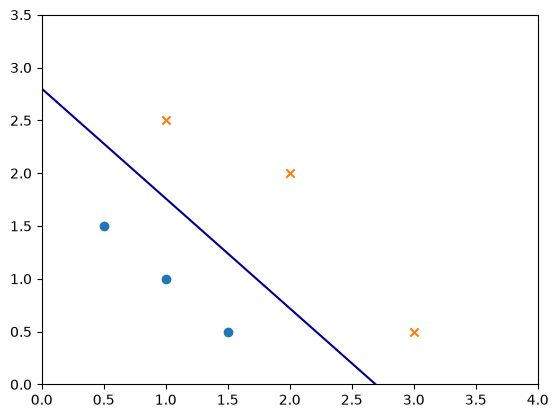

In [26]:

x0 = - b_out/w_out[0]
x1 = -b_out/w_out[1]
plt.plot([0,x0],[x1,0], c='darkblue')

plt.scatter(X_train[y_train==0,0],X_train[y_train==0,1], marker='o')
plt.scatter(X_train[y_train==1,0],X_train[y_train==1,1], marker='x')

plt.axis([0, 4, 0, 3.5])

